# TA-04: Prediksi Konsentrasi Polusi Udara PM2.5 (Beijing) Menggunakan LSTM
**Mata Praktikum:** Pembelajaran Mesin | **Dataset:** Beijing PM2.5 Data (UCI / Kaggle), 1 Jan 2010 – 31 Des 2014, per jam

**Rumusan masalah:** memprediksi konsentrasi PM2.5 (µg/m³) pada jam berikutnya berdasarkan data 24 jam sebelumnya (PM2.5 + variabel meteorologi).

## 1. Persiapan Library & Memuat Data

In [1]:
import os, random, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style='whitegrid')
os.makedirs('../images', exist_ok=True); os.makedirs('../model', exist_ok=True)

df = pd.read_csv('../data/PRSA_data_2010.1.1-2014.12.31.csv')
df.head()

I0000 00:00:1793322036.531591     119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793322048.650154     119 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793322055.321265     119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [2]:
print(df.shape)
df.info()
df.isna().sum()

(43824, 13)
<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  str    
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), str(1)
memory usage: 4.3 MB


No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64

## 2. Kolom Waktu sebagai Index (Bukti Data Time Series — sesuai TP-04)
Kolom `year, month, day, hour` digabung menjadi satu kolom `datetime` lalu dijadikan *index* DataFrame.

In [3]:
df['datetime'] = pd.to_datetime(df[['year','month','day','hour']])
df = df.set_index('datetime').drop(columns=['No','year','month','day','hour'])
print('Rentang waktu :', df.index.min(), 's/d', df.index.max())
print('Frekuensi     :', pd.infer_freq(df.index))
print('Index unik & terurut:', df.index.is_unique, df.index.is_monotonic_increasing)
df.head()

Rentang waktu : 2010-01-01 00:00:00 s/d 2014-12-31 23:00:00
Frekuensi     : h
Index unik & terurut: True True


,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
datetime,,,,,,,,
2010-01-01 00:00:00,NaN,-21,-11.0,1021.0,NW,1.79,0,0
2010-01-01 01:00:00,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2010-01-01 02:00:00,NaN,-21,-11.0,1019.0,NW,6.71,0,0
2010-01-01 03:00:00,NaN,-21,-14.0,1019.0,NW,9.84,0,0
2010-01-01 04:00:00,NaN,-20,-12.0,1018.0,NW,12.97,0,0


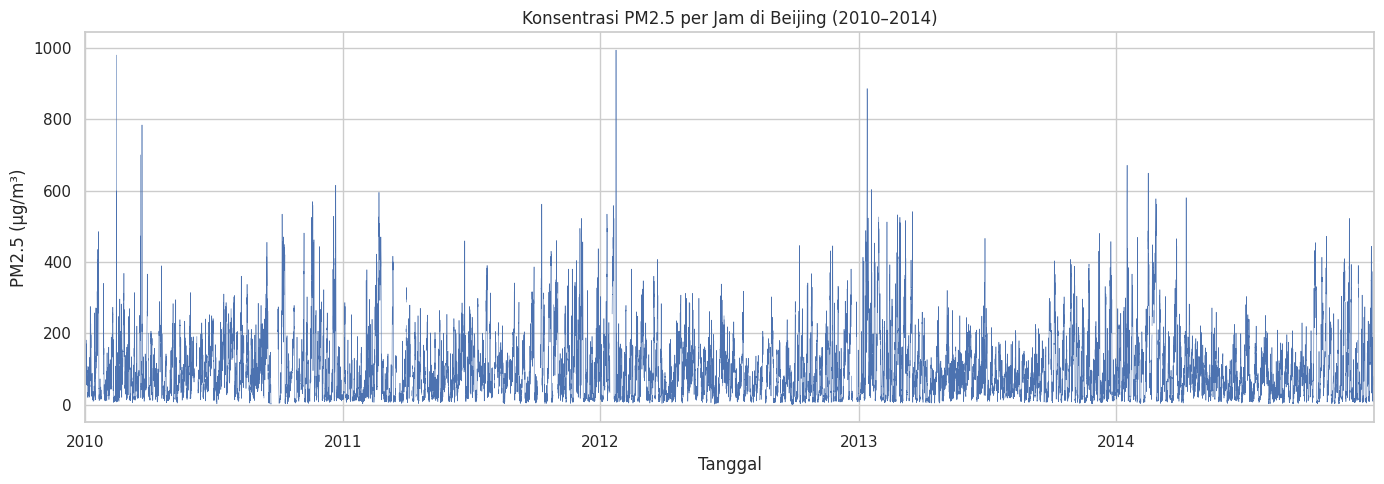

In [4]:
plt.figure(figsize=(14,5))
df['pm2.5'].plot(lw=0.4)
plt.title('Konsentrasi PM2.5 per Jam di Beijing (2010–2014)')
plt.xlabel('Tanggal'); plt.ylabel('PM2.5 (µg/m³)'); plt.grid(True)
plt.tight_layout(); plt.savefig('../images/01_line_plot_pm25.png', dpi=130); plt.show()

## 3. EDA: Tren, Musiman, dan Pola Lain

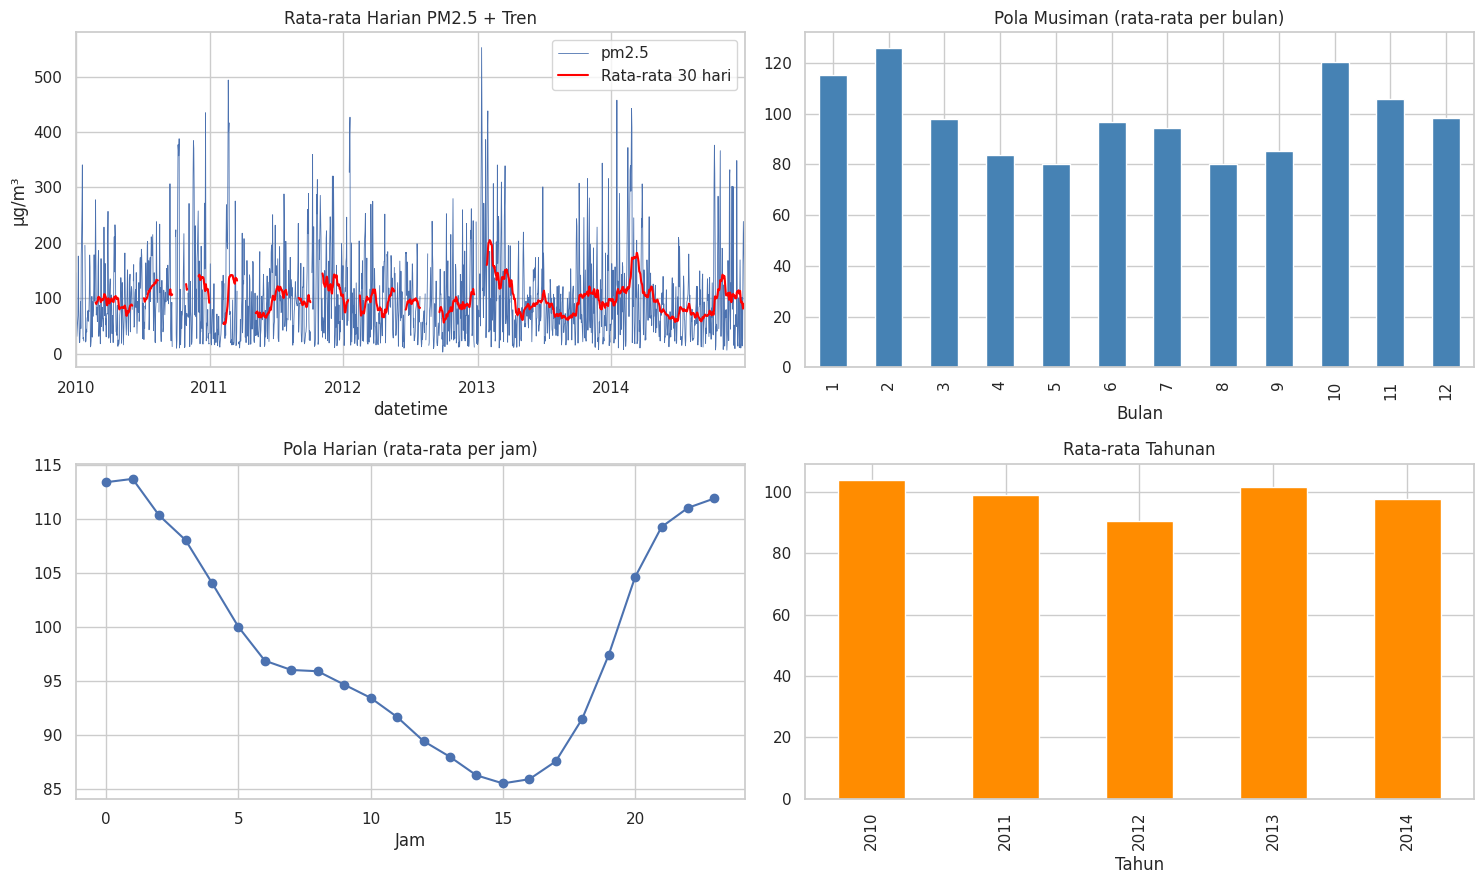

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
df['pm2.5'].resample('D').mean().plot(ax=ax[0,0], lw=0.6)
df['pm2.5'].resample('D').mean().rolling(30).mean().plot(ax=ax[0,0], color='red', lw=1.5, label='Rata-rata 30 hari')
ax[0,0].set_title('Rata-rata Harian PM2.5 + Tren'); ax[0,0].legend(); ax[0,0].set_ylabel('µg/m³')
df.groupby(df.index.month)['pm2.5'].mean().plot(kind='bar', ax=ax[0,1], color='steelblue')
ax[0,1].set_title('Pola Musiman (rata-rata per bulan)'); ax[0,1].set_xlabel('Bulan')
df.groupby(df.index.hour)['pm2.5'].mean().plot(ax=ax[1,0], marker='o')
ax[1,0].set_title('Pola Harian (rata-rata per jam)'); ax[1,0].set_xlabel('Jam')
df.groupby(df.index.year)['pm2.5'].mean().plot(kind='bar', ax=ax[1,1], color='darkorange')
ax[1,1].set_title('Rata-rata Tahunan'); ax[1,1].set_xlabel('Tahun')
plt.tight_layout(); plt.savefig('../images/02_eda_pola.png', dpi=130); plt.show()

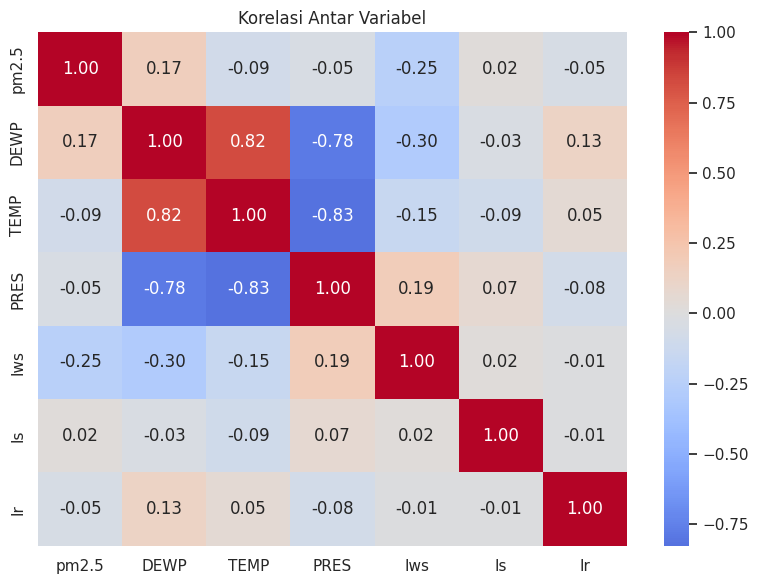

count    41757.000000
mean        98.613215
std         92.050387
min          0.000000
25%         29.000000
50%         72.000000
75%        137.000000
max        994.000000
Name: pm2.5, dtype: float64

Distribusi arah angin (cbwd):
cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64


In [6]:
num = df.select_dtypes('number')
plt.figure(figsize=(8,6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi Antar Variabel'); plt.tight_layout()
plt.savefig('../images/03_korelasi.png', dpi=130); plt.show()
print(df['pm2.5'].describe())
print('\nDistribusi arah angin (cbwd):'); print(df['cbwd'].value_counts())

1     0.966
2     0.920
3     0.874
6     0.748
12    0.568
24    0.402
48    0.156
72    0.074
dtype: float64


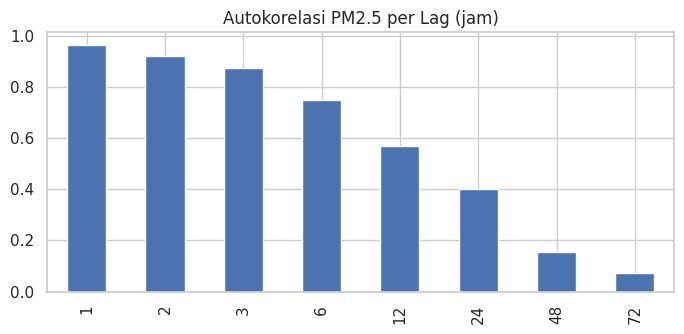

In [7]:
# Autokorelasi PM2.5: seberapa kuat nilai sekarang bergantung pada nilai sebelumnya
s = df['pm2.5'].interpolate()
lags = [1,2,3,6,12,24,48,72]
ac = pd.Series({l: s.autocorr(l) for l in lags})
print(ac.round(3))
ac.plot(kind='bar', figsize=(7,3.5), title='Autokorelasi PM2.5 per Lag (jam)'); plt.tight_layout()
plt.savefig('../images/04_autokorelasi.png', dpi=130); plt.show()

## 4. Pembersihan Data
- `pm2.5` memiliki *missing value* (±4,7%). Baris awal (24 jam pertama, 1 Jan 2010) kosong total → **dihapus**.
- *Gap* sisanya diisi **interpolasi linear berbasis waktu** agar deret tetap kontinu per jam (syarat *windowing*).
- Arah angin `cbwd` (kategorikal) → *one-hot encoding*.

In [8]:
n_na = df['pm2.5'].isna().sum()
df = df.iloc[24:].copy()                        # buang 24 jam awal yang kosong
df['pm2.5'] = df['pm2.5'].interpolate(method='time')
print('Missing awal:', n_na, '| sisa missing:', df['pm2.5'].isna().sum())
df = pd.get_dummies(df, columns=['cbwd'], dtype=float)
FEATURES = ['pm2.5','DEWP','TEMP','PRES','Iws','Is','Ir'] + sorted([c for c in df.columns if c.startswith('cbwd_')])
df = df[FEATURES]
print('Fitur:', FEATURES, '\nShape:', df.shape)
df.head()

Missing awal: 2067 | sisa missing: 0
Fitur: ['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'cbwd_NE', 'cbwd_NW', 'cbwd_SE', 'cbwd_cv'] 
Shape: (43800, 11)


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd_NE,cbwd_NW,cbwd_SE,cbwd_cv
datetime,,,,,,,,,,,
2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,1.79,0,0,0.0,0.0,1.0,0.0
2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,2.68,0,0,0.0,0.0,1.0,0.0
2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,3.57,0,0,0.0,0.0,1.0,0.0
2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,5.36,1,0,0.0,0.0,1.0,0.0
2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,6.25,2,0,0.0,0.0,1.0,0.0


## 5. Pembagian Data (Kronologis) & Scaling
Data time series **tidak boleh diacak**. Pembagian: 70% latih, 10% validasi, 20% uji. `MinMaxScaler` di-*fit* **hanya pada data latih** agar tidak terjadi *data leakage*.

In [9]:
n = len(df)
i_tr, i_va = int(n*0.70), int(n*0.80)
train_df, val_df, test_df = df.iloc[:i_tr], df.iloc[i_tr:i_va], df.iloc[i_va:]
print('Latih :', train_df.index.min(), '→', train_df.index.max(), len(train_df))
print('Valid :', val_df.index.min(), '→', val_df.index.max(), len(val_df))
print('Uji   :', test_df.index.min(), '→', test_df.index.max(), len(test_df))

scaler = MinMaxScaler(feature_range=(0,1)).fit(train_df.values)
train_s, val_s, test_s = (scaler.transform(d.values) for d in (train_df, val_df, test_df))

Latih : 2010-01-02 00:00:00 → 2013-07-02 10:00:00 30659
Valid : 2013-07-02 11:00:00 → 2013-12-31 23:00:00 4381
Uji   : 2014-01-01 00:00:00 → 2014-12-31 23:00:00 8760


## 6. Windowing (Sekuens) & Reshape 3D
`TIMESTEPS = 24` → data 24 jam terakhir dipakai untuk memprediksi PM2.5 jam ke-25. Bentuk input LSTM: `(samples, timesteps, features)`.
Agar sekuens awal di tiap subset punya konteks, jendela validasi/uji memakai sisa 24 jam dari subset sebelumnya.

In [10]:
TIMESTEPS = 24
def make_windows(arr, timesteps=TIMESTEPS, target_col=0):
    X, y = [], []
    for i in range(timesteps, len(arr)):
        X.append(arr[i-timesteps:i, :])
        y.append(arr[i, target_col])
    return np.array(X), np.array(y)

X_train, y_train = make_windows(train_s)
X_val,   y_val   = make_windows(np.vstack([train_s[-TIMESTEPS:], val_s]))
X_test,  y_test  = make_windows(np.vstack([val_s[-TIMESTEPS:],  test_s]))
N_FEAT = X_train.shape[2]
print('X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)
print('Format (samples, timesteps, features) =', X_train.shape)

X_train (30635, 24, 11) | X_val (4381, 24, 11) | X_test (8760, 24, 11)
Format (samples, timesteps, features) = (30635, 24, 11)


## 7. Membangun Model LSTM

In [11]:
model = Sequential([
    Input(shape=(TIMESTEPS, N_FEAT)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        19,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,417 (126.63 KB)

 Trainable params: 32,417 (126.63 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Pelatihan Model
*EarlyStopping* menghentikan pelatihan bila `val_loss` tidak membaik, dan mengembalikan bobot terbaik.

In [12]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]
history = model.fit(X_train, y_train, epochs=40, batch_size=64,
                    validation_data=(X_val, y_val), callbacks=callbacks, verbose=2, shuffle=False)

Epoch 1/40


479/479 - 10s - 20ms/step - loss: 0.0042 - val_loss: 0.0031 - learning_rate: 0.0010


Epoch 2/40


479/479 - 10s - 22ms/step - loss: 0.0023 - val_loss: 0.0019 - learning_rate: 0.0010


Epoch 3/40


...

479/479 - 10s - 22ms/step - loss: 5.9614e-04 - val_loss: 3.4407e-04 - learning_rate: 1.0000e-05


Epoch 36/40


479/479 - 10s - 21ms/step - loss: 6.0298e-04 - val_loss: 3.4319e-04 - learning_rate: 1.0000e-05


Epoch 36: early stopping


Restoring model weights from the end of the best epoch: 30.


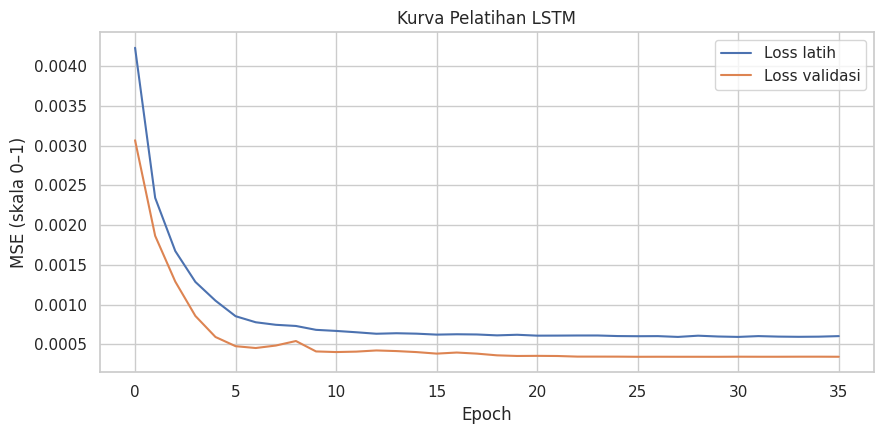

In [13]:
plt.figure(figsize=(9,4.5))
plt.plot(history.history['loss'], label='Loss latih'); plt.plot(history.history['val_loss'], label='Loss validasi')
plt.title('Kurva Pelatihan LSTM'); plt.xlabel('Epoch'); plt.ylabel('MSE (skala 0–1)'); plt.legend()
plt.tight_layout(); plt.savefig('../images/05_loss.png', dpi=130); plt.show()

## 9. Evaluasi pada Data Uji
Prediksi dan nilai aktual dikembalikan ke skala asli (*inverse transform*, µg/m³). Sebagai pembanding ditambahkan **baseline persistensi** (prediksi = nilai jam sebelumnya) — LSTM harus mengalahkan baseline ini agar bermakna.

In [14]:
D_MIN, D_SCALE = scaler.data_min_[0], scaler.scale_[0]
inv = lambda a: np.asarray(a).reshape(-1) / D_SCALE + D_MIN      # inverse transform kolom target

pred_test = np.clip(inv(model.predict(X_test, verbose=0)), 0, None)
y_true    = inv(y_test)
pred_val  = np.clip(inv(model.predict(X_val, verbose=0)), 0, None)
y_val_true = inv(y_val)
y_naive   = inv(X_test[:, -1, 0])                                  # baseline persistensi

def metrics(y, p):
    return dict(RMSE=float(np.sqrt(mean_squared_error(y, p))), MAE=float(mean_absolute_error(y, p)), R2=float(r2_score(y, p)))
res = {'LSTM (uji)': metrics(y_true, pred_test),
       'Baseline persistensi (uji)': metrics(y_true, y_naive),
       'LSTM (validasi)': metrics(y_val_true, pred_val)}
res_df = pd.DataFrame(res).T.round(3); print(res_df)
print(f"\nRata-rata PM2.5 data uji: {y_true.mean():.1f} µg/m³ → RMSE LSTM = {res['LSTM (uji)']['RMSE']/y_true.mean()*100:.1f}% dari rata-rata")

                              RMSE     MAE     R2
LSTM (uji)                  20.725  11.841  0.951
Baseline persistensi (uji)  21.913  11.824  0.945
LSTM (validasi)             18.401  11.159  0.947

Rata-rata PM2.5 data uji: 98.0 µg/m³ → RMSE LSTM = 21.2% dari rata-rata


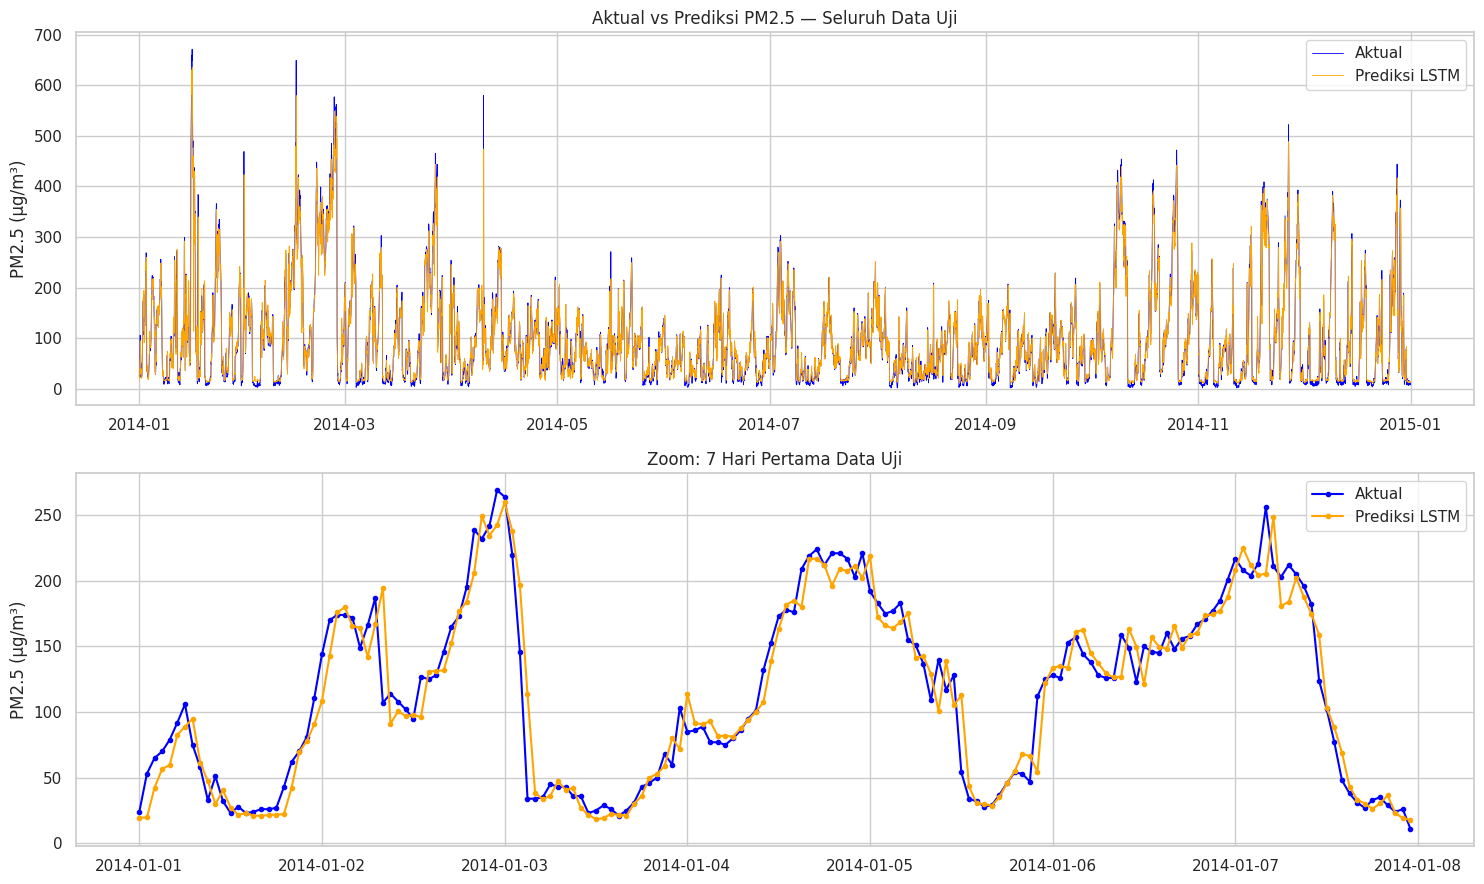

In [15]:
idx = test_df.index[-len(y_true):]
fig, ax = plt.subplots(2, 1, figsize=(15, 9))
ax[0].plot(idx, y_true, color='blue', lw=0.6, label='Aktual'); ax[0].plot(idx, pred_test, color='orange', lw=0.6, label='Prediksi LSTM')
ax[0].set_title('Aktual vs Prediksi PM2.5 — Seluruh Data Uji'); ax[0].set_ylabel('PM2.5 (µg/m³)'); ax[0].legend()
k = 24*7
ax[1].plot(idx[:k], y_true[:k], color='blue', marker='.', label='Aktual'); ax[1].plot(idx[:k], pred_test[:k], color='orange', marker='.', label='Prediksi LSTM')
ax[1].set_title('Zoom: 7 Hari Pertama Data Uji'); ax[1].set_ylabel('PM2.5 (µg/m³)'); ax[1].legend()
plt.tight_layout(); plt.savefig('../images/06_aktual_vs_prediksi.png', dpi=130); plt.show()

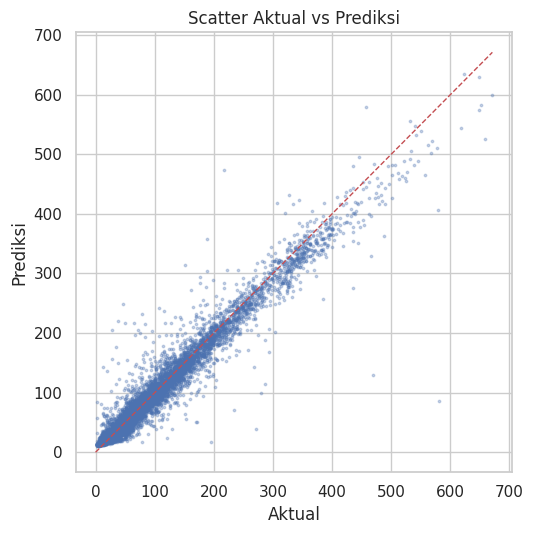

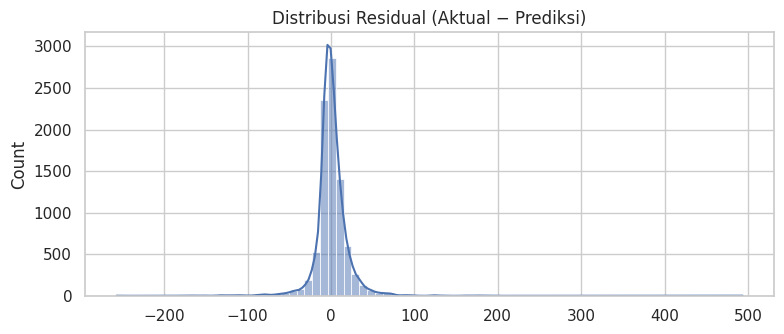

Mean residual: 0.72 | Std: 20.71


In [16]:
plt.figure(figsize=(5.5,5.5))
plt.scatter(y_true, pred_test, s=3, alpha=0.3)
m = max(y_true.max(), pred_test.max()); plt.plot([0,m],[0,m],'r--',lw=1)
plt.xlabel('Aktual'); plt.ylabel('Prediksi'); plt.title('Scatter Aktual vs Prediksi'); plt.tight_layout()
plt.savefig('../images/07_scatter.png', dpi=130); plt.show()
err = y_true - pred_test
plt.figure(figsize=(8,3.5)); sns.histplot(err, bins=80, kde=True); plt.title('Distribusi Residual (Aktual − Prediksi)')
plt.tight_layout(); plt.savefig('../images/08_residual.png', dpi=130); plt.show()
print('Mean residual:', err.mean().round(2), '| Std:', err.std().round(2))

In [17]:
# Kinerja per kategori kualitas udara (skala US EPA disederhanakan)
bins = [-1,35,75,150,1000]; labels = ['Baik (≤35)','Sedang (35–75)','Tidak sehat (75–150)','Sangat tidak sehat (>150)']
cat = pd.cut(y_true, bins=bins, labels=labels)
per_cat = pd.DataFrame({'cat':cat,'ae':np.abs(err),'se':err**2}).groupby('cat', observed=True).agg(n=('ae','size'), MAE=('ae','mean'), RMSE=('se', lambda s: np.sqrt(s.mean()))).round(2)
print(per_cat)

                              n    MAE   RMSE
cat                                          
Baik (≤35)                 2568   6.77  11.10
Sedang (35–75)             1984   9.89  16.59
Tidak sehat (75–150)       2442  11.95  18.30
Sangat tidak sehat (>150)  1766  21.27  34.33


## 10. Penyimpanan Model & Scaler
Model disimpan dalam format `.h5` (sesuai ketentuan tugas) dan `.keras`; *scaler* disimpan dengan **Joblib**. Metadata (fitur, timesteps, metrik) disimpan agar aplikasi Flask konsisten dengan notebook.

In [18]:
model.save('../model/pm25_lstm.h5')
model.save('../model/pm25_lstm.keras')
joblib.dump(scaler, '../model/scaler.joblib')
meta = dict(timesteps=TIMESTEPS, features=FEATURES, target='pm2.5',
            split=dict(train_end=str(train_df.index[-1]), val_end=str(val_df.index[-1]), test_start=str(test_df.index[0])),
            metrics={k:{m:round(v,3) for m,v in d.items()} for k,d in res.items()})
json.dump(meta, open('../model/meta.json','w'), indent=2)
# data bersih untuk aplikasi web
df.to_csv('../data/pm25_clean.csv', index_label='datetime')
res_df.to_csv('../model/metrics.csv'); per_cat.to_csv('../model/metrics_per_kategori.csv')
print(os.listdir('../model'))

['metrics_per_kategori.csv', 'pm25_lstm.keras', 'metrics.csv', 'meta.json', 'pm25_lstm.h5', 'scaler.joblib']


In [19]:
# Uji muat ulang (memastikan file tersimpan benar)
m2 = tf.keras.models.load_model('../model/pm25_lstm.h5', compile=False)
s2 = joblib.load('../model/scaler.joblib')
print('Selisih prediksi model asli vs muat-ulang:', float(np.abs(m2.predict(X_test[:50], verbose=0) - model.predict(X_test[:50], verbose=0)).max()))

Selisih prediksi model asli vs muat-ulang: 0.0


## 11. Kesimpulan Singkat
Lihat tabel metrik di atas dan laporan lengkap (DOCX/PDF). Model LSTM dibandingkan dengan baseline persistensi untuk menilai nilai tambah sebenarnya.